# Chapitre 1 - Cours 1 : penser les systèmes de données, l'exemple des timelines de Twitter

Le chapitre 1 pose le vocabulaire de tout le livre : **fiabilité**, **scalabilité** et
**maintenabilité**. Pour rendre la scalabilité concrète, le livre décrit la charge de
Twitter et la façon dont l'entreprise construit les timelines (fils d'accueil) de ses
utilisateurs. Ce notebook couvre la section *Thinking About Data Systems* et la
sous-section *Describing Load* de la section *Scalability*.

**Plan.**

- Penser les systèmes de données : des briques assemblées en un système composite.
1. Le schéma relationnel et la requête de timeline, exécutés sur SQLite.
2. Les ordres de grandeur de la charge, et ce qu'ils coûtent.
3. Le fan-out à l'écriture : des timelines matérialisées.
4. La loi de puissance des abonnés et le problème des célébrités.
5. L'approche hybride et le choix d'un seuil.
6. Décrire la charge : paramètres, moyennes et cas extrêmes.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## Penser les systèmes de données (section *Thinking About Data Systems*)

On range traditionnellement les outils en catégories bien séparées : bases de données,
caches, index de recherche, files de messages. Le livre défend une autre lecture : ces
catégories se brouillent (Redis sert de base et de file, Kafka de file durable qui
ressemble à une base), et surtout une application réelle en **assemble plusieurs**. Le
code applicatif devient alors le chef d'orchestre d'un **système de données composite**,
dont il doit garantir la cohérence : quand le cache est-il invalidé ? l'index est-il à
jour ? que se passe-t-il si l'un des composants tombe ?

Le schéma ci-dessous dessine une telle architecture. Le développeur qui l'écrit est
devenu, qu'il le veuille ou non, un **concepteur de système de données** : l'API qu'il
expose cache les détails, mais c'est à lui de garantir les propriétés de l'ensemble.

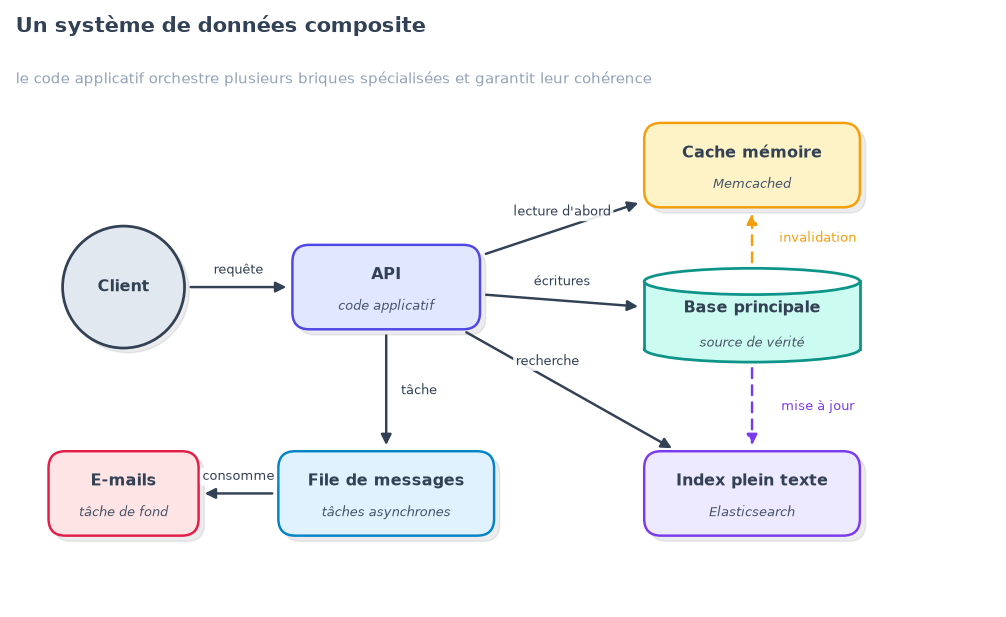

In [2]:
d = Diagram(10.5, 5.4, title="Un système de données composite",
            subtitle="le code applicatif orchestre plusieurs briques spécialisées et garantit leur cohérence")
d.box("client", 1.2, 3.4, "Client", kind="user", w=1.3, color=SLATE)
d.box("api", 4.0, 3.4, "API", sub="code applicatif", color=INDIGO, w=2.0)
d.box("cache", 7.9, 4.7, "Cache mémoire", sub="Memcached", color=AMBER, w=2.3)
d.box("db", 7.9, 3.1, "Base principale", sub="source de vérité", color=TEAL, kind="db", w=2.3, h=1.0)
d.box("idx", 7.9, 1.2, "Index plein texte", sub="Elasticsearch", color=VIOLET, w=2.3)
d.box("q", 4.0, 1.2, "File de messages", sub="tâches asynchrones", color=SKY, w=2.3)
d.box("mail", 1.2, 1.2, "E-mails", sub="tâche de fond", color=ROSE, w=1.6)
d.arrow("client", "api", "requête")
d.arrow("api", "cache", "lecture d'abord")
d.arrow("api", "db", "écritures", label_offset=(0, 0.2))
d.arrow("api", "idx", "recherche", label_pos=0.4)
d.arrow("db", "cache", "invalidation", style="dashed", color=AMBER, label_offset=(0.7, 0))
d.arrow("db", "idx", "mise à jour", style="dashed", color=VIOLET, label_offset=(0.7, 0))
d.arrow("api", "q", "tâche", label_offset=(0.35, 0))
d.arrow("q", "mail", "consomme")
d.show()

Les trois préoccupations qui structurent le chapitre se posent dès ce schéma :

- **fiabilité** : le système doit continuer à fonctionner correctement quand quelque
  chose se passe mal (panne d'un serveur, bogue, erreur humaine) ;
- **scalabilité** : quand la charge augmente (plus d'utilisateurs, plus de données), il
  doit exister des moyens raisonnables de suivre ;
- **maintenabilité** : au fil des années, de nombreuses personnes devront le faire
  tourner et le modifier, il faut que ce soit possible et productif.

> **À retenir.** Une application « gourmande en données » assemble des briques
> spécialisées (base, cache, index, file) ; celui qui les assemble conçoit un système
> de données et répond de sa fiabilité, de sa scalabilité et de sa maintenabilité.

## 1. Le schéma relationnel et la requête de timeline (section *Describing Load*)

**Le problème.** Chaque utilisateur doit voir sa **timeline d'accueil** : les messages
récents des comptes qu'il suit, du plus récent au plus ancien. Le modèle le plus direct
tient en trois tables : `users`, `posts` (avec l'identifiant de l'auteur et un
horodatage) et `follows` (une ligne par relation « A suit B »). La timeline est alors une
**jointure** : trouver les comptes suivis, leurs messages récents, trier et garder les
premiers.

Construisons ce schéma sur SQLite avec un graphe social synthétique de 5 000 comptes
(fonction `rq.social_graph` : la popularité suit une loi de puissance, nous y
reviendrons en section 4).

In [3]:
N_USERS = 5_000
follower, followee = rq.social_graph(N_USERS, mean_follows=50, alpha=1.2, seed=1)
n_followers, n_following = rq.degree_counts(follower, followee, N_USERS)

con = sqlite3.connect(":memory:")
con.executescript("""
CREATE TABLE users   (id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE posts   (id INTEGER PRIMARY KEY, sender_id INTEGER, timestamp REAL, text TEXT);
CREATE TABLE follows (follower_id INTEGER, followee_id INTEGER, PRIMARY KEY (follower_id, followee_id));
CREATE INDEX posts_by_sender ON posts (sender_id, timestamp);
""")
con.executemany("INSERT INTO users VALUES (?, ?)", ((i, f"user{i}") for i in range(N_USERS)))
con.executemany("INSERT INTO follows VALUES (?, ?)", zip(follower.tolist(), followee.tolist()))

# 40 messages par compte en moyenne, sur 30 jours, auteurs tirés uniformément
N_POSTS = 200_000
sender = rng.integers(0, N_USERS, N_POSTS)
ts = np.sort(rng.uniform(0, 30 * 86400, N_POSTS))
con.executemany("INSERT INTO posts VALUES (?, ?, ?, ?)",
                ((i, int(s), float(t), f"message {i}") for i, (s, t) in enumerate(zip(sender, ts))))
con.commit()
pd.DataFrame({"table": ["users", "posts", "follows"],
              "lignes": [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ["users", "posts", "follows"]]})

,table,lignes
0,users,5000
1,posts,200000
2,follows,205819


La requête de timeline, adaptée de celle du livre (avec une limite de 50 messages au
lieu de 1 000 pour notre petit jeu de données) :

In [4]:
TIMELINE_SQL = """
SELECT posts.id, posts.sender_id, posts.timestamp, users.name
  FROM posts
  JOIN follows ON posts.sender_id = follows.followee_id
  JOIN users   ON posts.sender_id = users.id
 WHERE follows.follower_id = ?
 ORDER BY posts.timestamp DESC
 LIMIT 50
"""
for row in con.execute("EXPLAIN QUERY PLAN " + TIMELINE_SQL, (0,)):
    print(row[-1])

SEARCH follows USING COVERING INDEX sqlite_autoindex_follows_1 (follower_id=?)
SEARCH users USING INTEGER PRIMARY KEY (rowid=?)
SEARCH posts USING COVERING INDEX posts_by_sender (sender_id=?)
USE TEMP B-TREE FOR ORDER BY


Le plan de requête confirme l'intuition du livre : SQLite parcourt la liste des comptes
suivis (clé primaire de `follows`), va chercher pour chacun ses messages via l'index
`posts_by_sender`, puis **trie** l'ensemble dans une structure temporaire (`USE TEMP
B-TREE FOR ORDER BY`). Le travail est donc proportionnel au nombre de comptes suivis et à
leur activité, et non à la taille de la timeline demandée. Mesurons le temps de la
requête pour des utilisateurs qui suivent de quelques comptes à plusieurs centaines.

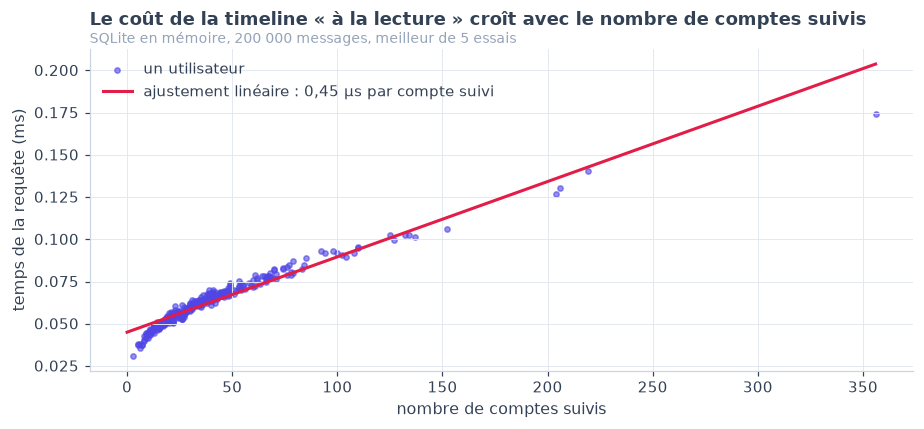

In [5]:
def time_query(sql, arg, repeat=5):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter()
        con.execute(sql, (arg,)).fetchall()
        best = min(best, time.perf_counter() - t0)
    return best * 1e3

sample_users = rng.choice(N_USERS, 300, replace=False)
mes = pd.DataFrame({"suivis": n_following[sample_users],
                    "ms": [time_query(TIMELINE_SQL, int(u)) for u in sample_users]})
coef = np.polyfit(mes.suivis, mes.ms, 1)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(mes.suivis, mes.ms, s=12, color=INDIGO, alpha=0.6, label="un utilisateur")
xs = np.linspace(0, mes.suivis.max(), 50)
ax.plot(xs, np.polyval(coef, xs), color=ROSE, label=f"ajustement linéaire : {coef[0] * 1e3:.2f} µs par compte suivi".replace(".", ","))
ax.set_xlabel("nombre de comptes suivis")
ax.set_ylabel("temps de la requête (ms)")
ax.set_title("Le coût de la timeline « à la lecture » croît avec le nombre de comptes suivis")
subtitle(ax, f"SQLite en mémoire, {fmt(N_POSTS)} messages, meilleur de 5 essais")
ax.legend()
plt.tight_layout(); plt.show()

Le coût est à peu près **linéaire** dans le nombre de comptes suivis : chaque compte
suivi ajoute une recherche dans l'index des messages et des lignes à trier. Sur une
machine et quelques milliers de comptes, c'est rapide. Le problème n'est pas une requête,
c'est leur **nombre** : passons aux ordres de grandeur.

> **À retenir.** La timeline relationnelle est une jointure suivie d'un tri. Son coût
> est proportionnel au nombre de comptes suivis : c'est un calcul **à la lecture**,
> refait à chaque consultation.

## 2. Ordres de grandeur de la charge

Le livre donne des chiffres de l'ordre de ceux d'un grand réseau social. Nous les
mettons dans un dictionnaire pour calculer les conséquences des deux stratégies.

In [6]:
# chiffres de Twitter cités par le livre (novembre 2012)
CHARGE = dict(publications_par_s=4_600, pic_publications_par_s=12_000,
              lectures_timeline_par_s=300_000, abonnes_moyen=75)

Une remarque simple mais utile : dans un graphe fermé, **le nombre moyen d'abonnés est
égal au nombre moyen d'abonnements** (chaque arête est un abonnement pour l'un et un
abonné pour l'autre). On peut donc utiliser le même chiffre pour les deux.

- **À la lecture** (requête SQL) : chaque lecture de timeline consulte les messages de
  chaque compte suivi, soit `lectures × abonnements` accès ;
- **à l'écriture** (fan-out) : chaque message est copié dans la timeline de chaque
  abonné, soit `publications × abonnés` écritures, et une lecture ne coûte qu'un accès.

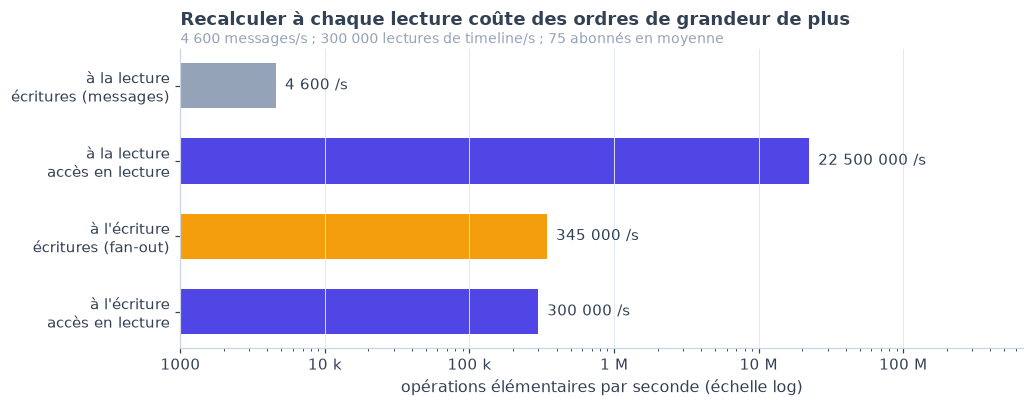

,stratégie,opération,par seconde
0,à la lecture,écritures (messages),4 600
1,à la lecture,accès en lecture,22 500 000
2,à l'écriture,écritures (fan-out),345 000
3,à l'écriture,accès en lecture,300 000


In [7]:
c = CHARGE
couts = pd.DataFrame({
    "stratégie": ["à la lecture", "à la lecture", "à l'écriture", "à l'écriture"],
    "opération": ["écritures (messages)", "accès en lecture", "écritures (fan-out)", "accès en lecture"],
    "par seconde": [c["publications_par_s"], c["lectures_timeline_par_s"] * c["abonnes_moyen"],
                    c["publications_par_s"] * c["abonnes_moyen"], c["lectures_timeline_par_s"]],
})
fig, ax = plt.subplots(figsize=(9.5, 3.8))
labels = [f"{a}\n{b}" for a, b in zip(couts["stratégie"], couts["opération"])]
colors = [GRAY, INDIGO, AMBER, INDIGO]
ax.barh(labels[::-1], couts["par seconde"].values[::-1], color=colors[::-1], height=0.6)
ax.set_xscale("log"); rq.plain_log_axis(ax, "x")
for i, v in enumerate(couts["par seconde"].values[::-1]):
    ax.text(v * 1.15, i, fmt(v) + " /s", va="center", fontsize=9.5)
ax.set_xlim(1e3, couts["par seconde"].max() * 30)
ax.set_xlabel("opérations élémentaires par seconde (échelle log)")
ax.set_title("Recalculer à chaque lecture coûte des ordres de grandeur de plus")
subtitle(ax, f"{fmt(c['publications_par_s'])} messages/s ; {fmt(c['lectures_timeline_par_s'])} lectures de timeline/s ; "
             f"{c['abonnes_moyen']} abonnés en moyenne")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
couts.assign(**{"par seconde": couts["par seconde"].map(fmt)})

Avec les chiffres de 2012, calculer la timeline à la lecture exige 22,5 millions d'accès
par seconde ; la diffuser à l'écriture n'en demande que 345 000 (plus 300 000 lectures de
cache). L'écart vient du **rapport lectures/écritures** : on consulte sa timeline près de
65 fois plus souvent qu'on ne publie. Il vaut donc mieux faire le travail au moment de
l'écriture, rare, qu'au moment de la lecture, fréquente. C'est l'argument qui a conduit
Twitter à passer de la première à la seconde approche.

Et ce n'est que le cas **moyen**. Les pointes de publication multiplient le coût du
fan-out, mais celui-ci peut être **différé** : on met les livraisons en file d'attente et
on accepte que les messages apparaissent un peu plus tard chez les abonnés. Les lectures,
elles, restent rapides puisqu'elles sont servies depuis le cache.

> **À retenir.** La charge s'exprime par quelques **paramètres** (publications/s,
> lectures/s, abonnés moyens) dont les produits donnent le coût de chaque architecture.
> Quand les lectures dominent, déplacer le travail vers l'écriture est payant.

## 3. Le fan-out à l'écriture : des timelines matérialisées (section *Describing Load*)

**L'idée.** Tenir, pour chaque utilisateur, une structure contenant sa timeline déjà
calculée, comme une **boîte aux lettres**. Quand quelqu'un publie, on cherche ses abonnés
et on dépose le message dans chacune de leurs boîtes. Une lecture n'est plus qu'une
consultation de cache. Le facteur par lequel une requête initiale se multiplie en
requêtes en aval s'appelle le **fan-out** (« éventail »). La timeline est une **donnée
dérivée** : on peut toujours la recalculer depuis les tables, c'est un **cache** du
résultat de la requête, ce qu'on appelle une **vue matérialisée**.

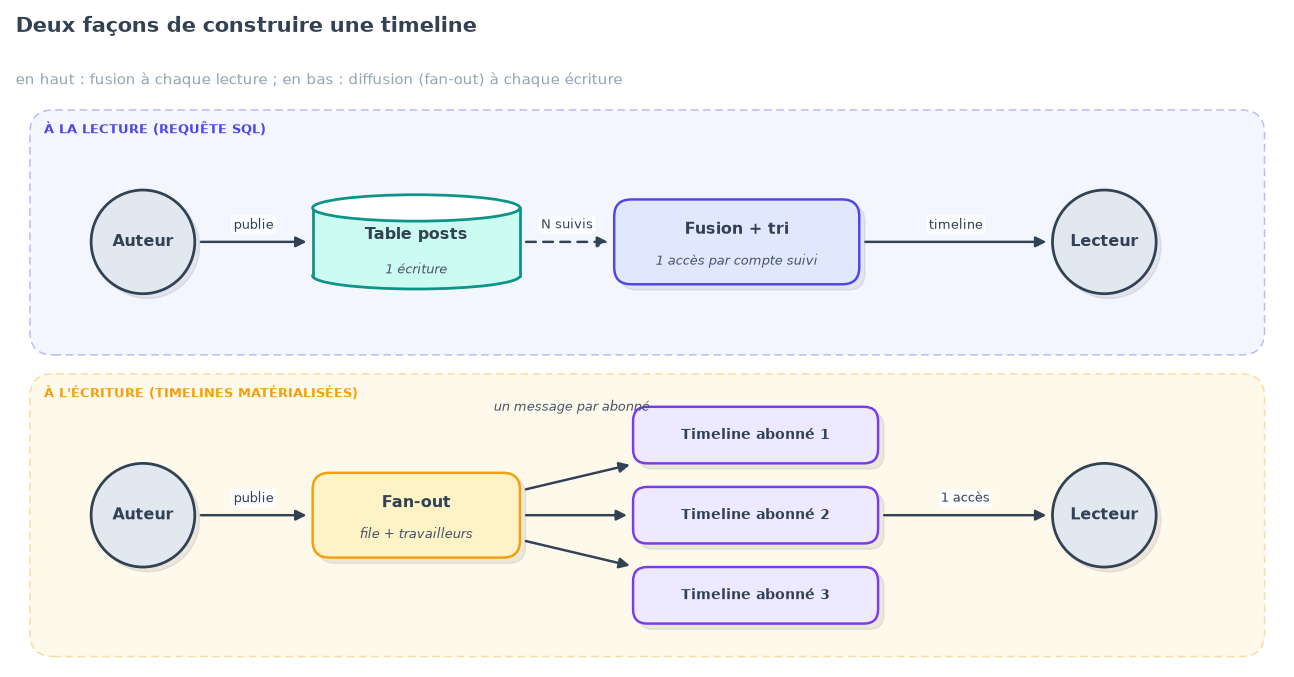

In [8]:
d = Diagram(13.5, 6.0, title="Deux façons de construire une timeline",
            subtitle="en haut : fusion à chaque lecture ; en bas : diffusion (fan-out) à chaque écriture")
d.group(0.2, 3.3, 13.3, 5.9, "à la lecture (requête SQL)", color=INDIGO)
d.box("a1", 1.4, 4.5, "Auteur", kind="user", w=1.1, color=SLATE)
d.box("p1", 4.3, 4.5, "Table posts", sub="1 écriture", color=TEAL, kind="db", w=2.2, h=1.0)
d.box("m1", 7.7, 4.5, "Fusion + tri", sub="1 accès par compte suivi", color=INDIGO, w=2.6)
d.box("l1", 11.6, 4.5, "Lecteur", kind="user", w=1.1, color=SLATE)
d.arrow("a1", "p1", "publie")
d.arrow("p1", "m1", "N suivis", style="dashed")
d.arrow("m1", "l1", "timeline")
d.group(0.2, 0.1, 13.3, 3.1, "à l'écriture (timelines matérialisées)", color=AMBER)
d.box("a2", 1.4, 1.6, "Auteur", kind="user", w=1.1, color=SLATE)
d.box("f2", 4.3, 1.6, "Fan-out", sub="file + travailleurs", color=AMBER, w=2.2)
for i, y in enumerate([2.45, 1.6, 0.75]):
    d.box(f"c{i}", 7.9, y, f"Timeline abonné {i + 1}", color=VIOLET, w=2.6, h=0.6, fontsize=9)
d.box("l2", 11.6, 1.6, "Lecteur", kind="user", w=1.1, color=SLATE)
d.arrow("a2", "f2", "publie")
for i in range(3):
    d.arrow("f2", f"c{i}")
d.arrow("c1", "l2", "1 accès")
d.note(5.95, 2.75, "un message par abonné", fontsize=8.5)
d.show()

Implémentons les deux stratégies (classes `rq.PullTimelines` et `rq.PushTimelines`) et
vérifions qu'elles renvoient **exactement les mêmes timelines**, tout en comptant les
opérations élémentaires de chacune. On rejoue les six premiers jours : 40 000 messages et
80 000 lectures de timeline (deux lectures par message, un rapport très prudent par
rapport au cas réel).

In [9]:
pull = rq.PullTimelines(follower, followee, N_USERS, k=50)
push = rq.PushTimelines(follower, followee, N_USERS, k=50)
REPLAY = 40_000
readers = rng.integers(0, N_USERS, 2 * REPLAY)
read_times = np.sort(rng.uniform(0, ts[REPLAY - 1], readers.size))
ok = 0
i_post = 0
for j, (u, t) in enumerate(zip(readers, read_times)):
    while i_post < REPLAY and ts[i_post] <= t:
        for s in (pull, push):
            s.post(int(sender[i_post]), float(ts[i_post]), "")
        i_post += 1
    a, b = pull.timeline(int(u)), push.timeline(int(u))
    if j % 200 == 0:                       # comparaison complète sur un échantillon
        ok += (a == b)
print(f"timelines identiques sur l'échantillon : {ok}/{(readers.size + 199) // 200}")
pd.DataFrame({"écritures": [pull.write_ops, push.write_ops], "lectures": [pull.read_ops, push.read_ops]},
             index=["à la lecture", "à l'écriture"]).assign(total=lambda df: df.sum(axis=1))

timelines identiques sur l'échantillon : 400/400


,écritures,lectures,total
à la lecture,39999,3294288,3334287
à l'écriture,1671531,80000,1751531


Les deux structures donnent les mêmes résultats (c'est la définition d'une vue
matérialisée correcte). Mais le travail est réparti très différemment : le fan-out à
l'écriture multiplie les écritures par le nombre moyen d'abonnés (une quarantaine ici)
et ramène chaque lecture à un seul accès. Même avec seulement deux lectures par message,
il fait moins de travail au total.

Le prix à payer : **plus de travail à l'écriture** et un délai avant qu'un message
n'apparaisse chez tous les abonnés. Ce délai devient critique pour certains comptes.

> **À retenir.** Une timeline matérialisée est un cache du résultat de la requête, tenu
> à jour à chaque écriture. On échange du travail à la lecture contre du travail à
> l'écriture, au prix d'une donnée dérivée à maintenir cohérente.